# ĐỀ 2 - Bài làm thi giữa kỳ môn Khai phá Web

**Họ tên:** ................................  **MSSV:** ................................  **STT:** 1

Bài làm được chia theo đúng cấu trúc đề bài: **Câu 1** (thu thập & trích xuất dữ liệu web)
và **Câu 2** (tiền xử lý & khám phá dữ liệu văn bản).

> Toàn bộ code trong notebook chỉ đọc dữ liệu trong thư mục `Data/` (không gọi Internet),
> và ghi kết quả vào 2 thư mục `Cau1/` và `Cau2/` bằng **đường dẫn tương đối** (relative
> path) tính từ thư mục chứa notebook này -- đúng theo yêu cầu đề bài, để khi nộp bài,
> giám khảo mở lại thư mục `<STT>_HoTen/` và chạy notebook vẫn hoạt động bình thường mà
> không cần sửa lại đường dẫn.

## 0. Import thư viện và cấu hình chung

In [13]:
# --- Thư viện xử lý file / đường dẫn ---
import os          # làm việc với đường dẫn file (os.path.join, os.makedirs, ...)
import re          # biểu thức chính quy (regex) để tìm/thay thế chuỗi
import csv          # đọc/ghi file CSV một cách an toàn (tự động xử lý dấu phẩy trong chuỗi)
import unicodedata  # dùng để "bỏ dấu" tiếng Việt (giải thích kỹ ở Câu 2c)

# --- Thư viện xử lý dữ liệu dạng bảng ---
import pandas as pd

# --- Thư viện xử lý HTML (Câu 1) ---
from bs4 import BeautifulSoup

# --- Thư viện đếm tần suất (Câu 2d) ---
from collections import Counter

# --- Thư viện tách từ tiếng Việt (Câu 2c) ---
from underthesea import word_tokenize

# --- Thư viện vẽ biểu đồ và wordcloud (Câu 2e) ---
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Toàn bộ đường dẫn dưới đây đều là đường dẫn TƯƠNG ĐỐI, tính từ thư mục
# chứa file notebook này -- không dùng đường dẫn tuyệt đối (vd "D:/...")
# để bài làm chạy được ở bất kỳ máy nào, kể cả sau khi đổi tên thư mục nộp bài.
os.makedirs("Cau1", exist_ok=True)
os.makedirs("Cau2", exist_ok=True)

print("Thư mục làm việc hiện tại (cwd):", os.getcwd())
print("Đã import xong thư viện và tạo thư mục Cau1/, Cau2/")

Thư mục làm việc hiện tại (cwd): d:\Workspace\KPW\class\GK\1_de2
Đã import xong thư viện và tạo thư mục Cau1/, Cau2/


## Câu 1. Thu thập và trích xuất dữ liệu web

Dữ liệu là 2 file HTML tĩnh (`page1.html`, `page2.html`) mô phỏng trang danh mục
**điện thoại**. Mỗi sản phẩm nằm trong thẻ `<article class="product-card">`.

### a) Đọc page1.html bằng BeautifulSoup (parser html5lib), in tên 4 sản phẩm

Lý do dùng parser **html5lib** thay vì `html.parser` mặc định: `html5lib` mô phỏng đúng
cách trình duyệt phân tích HTML (tự sửa lỗi thẻ mở/đóng không khớp, thiếu thẻ, ...), giúp
kết quả ổn định hơn với HTML "không sạch". Ở đây dữ liệu đã chuẩn nên `html.parser` cũng
sẽ ra kết quả tương tự, nhưng ta dùng html5lib theo đúng yêu cầu đề bài.

In [14]:
with open(r"Data/Chuong 2/page1.html", encoding="utf-8") as f:
    # html5lib đọc và "sửa" HTML trước khi trả về cây DOM cho BeautifulSoup duyệt
    soup = BeautifulSoup(f, "html5lib")

# .select(".product-card") = tìm tất cả thẻ có class="product-card" (giống CSS selector)
# ưu điểm so với find_all("article", class_="product-card"): ngắn gọn, dễ đọc
for card in soup.select(".product-card"):
    ten_sp = card.select_one(".product-name").get_text(strip=True)
    print(ten_sp)

Nova X1 128GB
Orion Lite 5G
Zen Pro Max
Aster Mini


### b) Bóc tách 4 trường từ cả 2 file, lưu vào `Cau1/dien_thoai_tho.csv`

Trường hợp cần chú ý: sản phẩm **không có khuyến mãi** (không tồn tại thẻ `.promotion`
trong HTML) thì `card.select_one(".promotion")` sẽ trả về `None`. Nếu gọi `.get_text()`
trực tiếp trên `None` sẽ bị lỗi `AttributeError`. Vì vậy phải kiểm tra `is not None`
trước khi lấy text, và để trống (`""`) khi thiếu -- đúng như đề bài yêu cầu.

In [15]:
def boc_tach_1_file(duong_dan):
    """Đọc 1 file HTML sản phẩm, trả về list[dict] với 4 trường yêu cầu."""
    with open(duong_dan, encoding="utf-8") as f:
        soup = BeautifulSoup(f, "html5lib")

    ket_qua = []
    for card in soup.select(".product-card"):
        ten_sp = card.select_one(".product-name").get_text(strip=True)
        gia_goc = card.select_one(".list-price").get_text(strip=True)
        gia_ban = card.select_one(".sale-price").get_text(strip=True)

        # --- Trường hợp đặc biệt: sản phẩm không có khuyến mãi ---
        the_khuyen_mai = card.select_one(".promotion")
        khuyen_mai = the_khuyen_mai.get_text(strip=True) if the_khuyen_mai is not None else ""

        ket_qua.append({
            "ten_sp": ten_sp,
            "gia_goc": gia_goc,
            "gia_ban": gia_ban,
            "khuyen_mai": khuyen_mai,
        })
    return ket_qua


# Duyệt CẢ HAI file HTML và gộp lại thành 1 danh sách duy nhất (4 + 4 = 8 sản phẩm)
danh_sach_tho = boc_tach_1_file(r"Data/Chuong 2/page1.html") + boc_tach_1_file(r"Data/Chuong 2/page2.html")

print("Số dòng dữ liệu:", len(danh_sach_tho))  # phải đúng bằng 8
assert len(danh_sach_tho) == 8, "Đề bài yêu cầu đúng 8 dòng dữ liệu!"

# Ghi ra CSV bằng csv.DictWriter -- tự động đặt dấu ngoặc kép quanh chuỗi có dấu phẩy
with open(r"Cau1/dien_thoai_tho.csv", "w", encoding="utf-8", newline="") as f:
    ghi = csv.DictWriter(f, fieldnames=["ten_sp", "gia_goc", "gia_ban", "khuyen_mai"])
    ghi.writeheader()
    ghi.writerows(danh_sach_tho)

pd.read_csv(r"Cau1/dien_thoai_tho.csv")

Số dòng dữ liệu: 8


,ten_sp,gia_goc,gia_ban,khuyen_mai
0,Nova X1 128GB,12.990.000 đ,11.490.000 đ,Tặng ốp lưng silicon
1,Orion Lite 5G,9.450.000 đ,8.990.000 đ,Giảm thêm 200.000 đ qua mã APP
2,Zen Pro Max,18.750.000 đ,15.990.000 đ,Trả góp 0 phần trăm
3,Aster Mini,6.200.000 đ,6.200.000 đ,NaN
4,Pixelion Fold,28.990.000 đ,24.490.000 đ,Tặng tai nghe không dây
5,Vega Note S,14.800.000 đ,13.690.000 đ,Bảo hành 24 tháng
6,Raptor Gaming Phone,21.500.000 đ,16.125.000 đ,Tặng tay cầm chơi game
7,Mira Go,7.890.000 đ,7.190.000 đ,Giảm giá sinh viên


### c) Làm sạch dữ liệu, lưu vào `Cau1/dien_thoai_sach.csv`

Giá trong file thô có dạng chuỗi `"21.990.000 đ"` (dấu `.` là dấu phân cách hàng nghìn,
kèm đơn vị `đ`). Để đổi về số nguyên VND, cách an toàn nhất là **loại bỏ mọi ký tự
không phải chữ số** bằng regex `[^\d]`, rồi `int(...)` phần còn lại -- cách này hoạt động
dù dấu phân cách là `.`, khoảng trắng hay ký tự tiền tệ nằm trước/sau.

In [16]:
def doi_sang_so_nguyen_vnd(chuoi_gia):
    """Ví dụ: '21.990.000 đ' -> 21990000. Bỏ tất cả ký tự không phải chữ số."""
    chi_so = re.sub(r"[^\d]", "", chuoi_gia)
    return int(chi_so)


danh_sach_sach = []
for dong in danh_sach_tho:
    gia_goc_vnd = doi_sang_so_nguyen_vnd(dong["gia_goc"])
    gia_ban_vnd = doi_sang_so_nguyen_vnd(dong["gia_ban"])

    # Trường hợp khuyen_mai rỗng (đã để "" ở bước trước) -> thay bằng câu mặc định
    khuyen_mai = dong["khuyen_mai"] if dong["khuyen_mai"] else "Không có khuyến mại"

    # Trường hợp đặc biệt: gia_goc == gia_ban (không giảm giá) -> ty_le_giam = 0.0
    # Công thức round(..., 2) giữ đúng 2 chữ số thập phân như đề bài yêu cầu
    ty_le_giam = round((gia_goc_vnd - gia_ban_vnd) / gia_goc_vnd * 100, 2)

    danh_sach_sach.append({
        "ten_sp": dong["ten_sp"],
        "gia_goc_vnd": gia_goc_vnd,
        "gia_ban_vnd": gia_ban_vnd,
        "khuyen_mai": khuyen_mai,
        "ty_le_giam": ty_le_giam,
    })

df_sach = pd.DataFrame(danh_sach_sach)
df_sach.to_csv(r"Cau1/dien_thoai_sach.csv", index=False, encoding="utf-8")
df_sach

,ten_sp,gia_goc_vnd,gia_ban_vnd,khuyen_mai,ty_le_giam
0,Nova X1 128GB,12990000,11490000,Tặng ốp lưng silicon,11.55
1,Orion Lite 5G,9450000,8990000,Giảm thêm 200.000 đ qua mã APP,4.87
2,Zen Pro Max,18750000,15990000,Trả góp 0 phần trăm,14.72
3,Aster Mini,6200000,6200000,Không có khuyến mại,0.00
4,Pixelion Fold,28990000,24490000,Tặng tai nghe không dây,15.52
5,Vega Note S,14800000,13690000,Bảo hành 24 tháng,7.50
6,Raptor Gaming Phone,21500000,16125000,Tặng tay cầm chơi game,25.00
7,Mira Go,7890000,7190000,Giảm giá sinh viên,8.87


## Câu 2. Tiền xử lý và khám phá dữ liệu văn bản

Dữ liệu: `reviews_raw.csv` gồm 10 đánh giá **nhà hàng**, kèm theo 3 tệp
hỗ trợ: `emoji_map.csv` (bảng tra emoji/emoticon -> nghĩa chữ), `tu_dien_chuan_hoa.csv`
(bảng tra từ viết tắt/sai chính tả -> từ chuẩn), và `stopwords.txt` (danh sách từ dừng
-- sẽ giải thích một điểm rất dễ nhầm ở phần c bên dưới).

In [17]:
# Đọc dữ liệu gốc
df = pd.read_csv(r"Data/Chuong 3/reviews_raw.csv")

# Đọc bảng tra emoji/emoticon -> chữ (vd: '😍' -> 'yeu_thich')
emoji_map = dict(pd.read_csv(r"Data/Chuong 3/emoji_map.csv").values)

# Đọc từ điển chuẩn hóa -> từ chuẩn (vd: 'ks' -> 'khach san')
tu_dien = dict(pd.read_csv(r"Data/Chuong 3/tu_dien_chuan_hoa.csv").values)

# Đọc danh sách stop word (mỗi dòng 1 từ)
with open(r"Data/Chuong 3/stopwords.txt", encoding="utf-8") as f:
    stop_words = set(dong.strip() for dong in f if dong.strip())

print("Số dòng review:", len(df))
print("Bảng emoji:", emoji_map)
print("Từ điển chuẩn hóa:", tu_dien)
print("Số lượng stop word:", len(stop_words))
df

Số dòng review: 10
Bảng emoji: {'😍': 'yeu_thich', '😒': 'khong_hai_long', ':)': 'vui_ve', ':D': 'cuoi_lon'}
Từ điển chuẩn hóa: {'quan': 'nha hang', 'ok': 'tot', 'pvu': 'phuc vu', 'tolet': 'toilet', 'kg': 'khong'}
Số lượng stop word: 16


,id,review
0,NH01,<p>Quan 5 sao!!! Nhân viên phục vụ rất nhanh 😍...
1,NH02,"Món bún ngon, nước dùng đậm đà :) nhưng chỗ ng..."
2,NH03,"Đồ ăn ok, giá 350.000đ cho 2 khách là hợp lý."
3,NH04,"Tôi đặt bàn qua www.restaurant.example, xác nh..."
4,NH05,"Nhân viên nhiệt tình, nhưng món lên hơi lâu..."
5,NH06,"Quán gần nhà, vị trí tiện, sẽ quay lại :D"
6,NH07,"Món ăn nguội, phục vụ chậm 30 phút, tôi thất v..."
7,NH08,"<div>Không gian sạch sẽ, nhạc nhẹ và dễ chịu!<..."
8,NH09,"Pvu tốt nhưng tolet chưa sạch, tôi kg hài lòng."
9,NH10,"Thực đơn đa dạng, món mới ngon, đáng tiền 100%."


### a) Bước 1: làm sạch sơ bộ -- `Cau2/buoc1.csv`

Yêu cầu: chuyển chữ thường, xóa thẻ HTML, xóa URL, xóa chữ số, chuẩn hóa khoảng trắng.
**Giữ nguyên** emoji/emoticon/dấu câu (để xử lý ở bước b).

**Thứ tự thực hiện rất quan trọng:**
1. Xóa thẻ HTML **trước** -- vì nếu làm sau, dấu `<`, `>` có thể bị các bước regex khác
   làm biến dạng, khó nhận diện thẻ.
2. Chuyển chữ thường -- làm trước hay sau bước xóa URL/số đều không ảnh hưởng, nhưng làm
   ở đây cho đúng thứ tự liệt kê của đề bài.
3. Xóa URL (`http://...`, `www...`) -- phải xóa **trước khi xóa chữ số**, vì URL thường
   chứa số (vd `menu/1`), nếu xóa số trước sẽ để lại rác dạng `menu/`.
4. Xóa chữ số còn lại (giá tiền, ngày tháng, %).
5. Chuẩn hóa nhiều khoảng trắng liên tiếp (do các bước trên để lại) thành 1 khoảng trắng.

In [18]:
def buoc1_lam_sach_so_bo(text):
    # 1) Xóa thẻ HTML dạng <...> (vd <p>, </div>) bằng regex không tham lam '[^>]+'
    text = re.sub(r"<[^>]+>", " ", text)

    # 2) Chuyển về chữ thường
    text = text.lower()

    # 3) Xóa URL dạng http(s)://... hoặc www....  \S+ = chuỗi không có khoảng trắng
    text = re.sub(r"(https?://\S+|www\.\S+)", " ", text)

    # 4) Xóa chữ số (ví dụ: '30', '100', '1', '2')
    text = re.sub(r"\d+", " ", text)

    # 5) Chuẩn hóa khoảng trắng: nhiều space/tab liên tiếp -> 1 space, cắt 2 đầu
    text = re.sub(r"\s+", " ", text).strip()

    return text


df["review_buoc1"] = df["review"].apply(buoc1_lam_sach_so_bo)

# Chỉ lưu 2 cột theo đúng yêu cầu đề bài
df[["id", "review_buoc1"]].to_csv("Cau2/buoc1.csv", index=False, encoding="utf-8")
df[["id", "review_buoc1"]]

,id,review_buoc1
0,NH01,quan sao!!! nhân viên phục vụ rất nhanh 😍. xem...
1,NH02,"món bún ngon, nước dùng đậm đà :) nhưng chỗ ng..."
2,NH03,"đồ ăn ok, giá . đ cho khách là hợp lý."
3,NH04,tôi đặt bàn qua xác nhận rất nhanh!!!
4,NH05,"nhân viên nhiệt tình, nhưng món lên hơi lâu..."
5,NH06,"quán gần nhà, vị trí tiện, sẽ quay lại :d"
6,NH07,"món ăn nguội, phục vụ chậm phút, tôi thất vọng 😒"
7,NH08,"không gian sạch sẽ, nhạc nhẹ và dễ chịu!"
8,NH09,"pvu tốt nhưng tolet chưa sạch, tôi kg hài lòng."
9,NH10,"thực đơn đa dạng, món mới ngon, đáng tiền %."


### b) Bước 2: chuẩn hóa từ/emoji, xóa dấu câu -- `Cau2/buoc2.csv`

Yêu cầu: dùng `emoji_map.csv` và `tu_dien_chuan_hoa.csv` để thay thế, rồi xóa dấu câu
và chuẩn hóa khoảng trắng.

**3 "bẫy" (edge case) đã phát hiện khi kiểm tra dữ liệu thực tế, cần xử lý cẩn thận:**

1. **Emoticon bị lệch chữ hoa/thường**: bảng `emoji_map.csv` có key `':D'` (chữ D
   *viết hoa*), nhưng ở bước 1 ta đã `lower()` toàn bộ văn bản nên `':D'` đã thành
   `':d'`. Nếu so khớp y nguyên theo `emoji_map` sẽ **bỏ sót**, để lại ký tự rác `d`
   sau khi xóa dấu câu. => Phải `.lower()` cả key của `emoji_map` trước khi so sánh.
2. **Từ viết tắt có dấu gạch nối**: ví dụ `check-in`. Muốn nhận diện là `checkin`
   (đúng key trong từ điển chuẩn hóa), cần nối 2 ký tự chữ quanh dấu `-` lại với nhau
   (regex `(\w)-(\w)` -> `\1\2`) **trước khi** tra từ điển. Nếu không, `check-in` sẽ
   không khớp với từ gốc `checkin` và bị bỏ sót.
3. **Tránh thay nhầm vào giữa từ khác**: khi thay thế theo từ điển (vd `kg` -> `khong`),
   bắt buộc dùng ranh giới từ `\b...\b` để chỉ thay khi `kg` là **một từ độc lập**,
   không thay nhầm vào giữa một từ dài hơn tình cờ chứa chuỗi con `kg`.

Sau khi thay xong emoji + từ chuẩn hóa, mới xóa dấu câu còn lại (dùng `\w` giữ lại
chữ+số+gạch dưới, có hỗ trợ Unicode nên tiếng Việt có dấu vẫn được giữ nguyên).

In [24]:
def buoc2_chuan_hoa(text):
    # (1) Thay emoji/emoticon -> chữ, so khớp KHÔNG PHÂN BIỆT hoa/thường vì text
    #     đầu vào đã bị lowercase từ bước 1 (vd emoji_map có ':D' nhưng text là ':d')
    for ky_hieu in sorted(emoji_map, key=len, reverse=True):
        text = text.replace(ky_hieu.lower(), f" {emoji_map[ky_hieu]} ")

    # (2) Nối liền các từ bị ngăn cách bởi dấu gạch nối giữa 2 ký tự chữ
    #     vd: 'check-in' -> 'checkin' để khớp với từ điển chuẩn hóa
    text = re.sub(r"(\w)-(\w)", r"\1\2", text)

    # (3) Thay từ viết tắt/sai chính tả bằng từ chuẩn, dùng \b để chỉ khớp nguyên từ
    for tu_goc, tu_chuan in tu_dien.items():
        text = re.sub(rf"\b{re.escape(tu_goc)}\b", tu_chuan, text)

    # (4) Xóa dấu câu còn lại (giữ chữ, số, khoảng trắng - hỗ trợ Unicode tiếng Việt)
    text = re.sub(r"[^\w\s]", " ", text, flags=re.UNICODE)

    # (5) Chuẩn hóa lại khoảng trắng sau khi thay thế/xóa ở các bước trên
    text = re.sub(r"\s+", " ", text).strip()

    return text


df["review_buoc2"] = df["review_buoc1"].apply(buoc2_chuan_hoa)
df[["id", "review_buoc2"]].to_csv("Cau2/buoc2.csv", index=False, encoding="utf-8")
df[["id", "review_buoc2"]]

,id,review_buoc2
0,NH01,nha hang sao nhân viên phục vụ rất nhanh yeu_t...
1,NH02,món bún ngon nước dùng đậm đà vui_ve nhưng chỗ...
2,NH03,đồ ăn tot giá đ cho khách là hợp lý
3,NH04,tôi đặt bàn qua xác nhận rất nhanh
4,NH05,nhân viên nhiệt tình nhưng món lên hơi lâu
5,NH06,quán gần nhà vị trí tiện sẽ quay lại cuoi_lon
6,NH07,món ăn nguội phục vụ chậm phút tôi thất vọng k...
7,NH08,không gian sạch sẽ nhạc nhẹ và dễ chịu
8,NH09,phuc vu tốt nhưng toilet chưa sạch tôi khong h...
9,NH10,thực đơn đa dạng món mới ngon đáng tiền


### c) Bước 3: tách từ + loại stop word -- `Cau2/buoc3.csv`

Dùng `underthesea.word_tokenize(..., format="text")` để tách từ tiếng Việt (trả về
chuỗi, từ ghép nối bởi dấu gạch dưới `_`, vd `nhan_vien`).

**Bẫy quan trọng nhất trong toàn bộ đề bài**: mở file `stopwords.txt` sẽ thấy nó được
ghi **KHÔNG DẤU** (vd dòng chứa `nhung`, `hoi`, `qua`... không có dấu tiếng Việt), trong
khi văn bản sau tách từ vẫn còn đầy đủ dấu (vd token thực tế là `nhưng`, `hơi`, `quá`).
Nếu so sánh trực tiếp `token in stop_words`, hai chuỗi này **không bao giờ bằng nhau**
=> stop word sẽ KHÔNG BỊ loại bất kỳ từ nào, sai hoàn toàn yêu cầu đề bài!

Cách xử lý đúng: viết hàm `bo_dau()` chuyển token về dạng không dấu (dùng
`unicodedata.normalize` để tách dấu khỏi chữ cái rồi loại bỏ các dấu tổ hợp -
"combining mark", riêng chữ `đ` phải đổi tay vì nó không phải là "chữ e + dấu tổ hợp"),
rồi mới so sánh với danh sách stop word.

In [25]:
def bo_dau(chuoi):
    # Chuyển chuỗi tiếng Việt có dấu -> không dấu. Vd: 'nhưng' -> 'nhung'.
    # NFD tách ký tự có dấu thành 'chữ cái gốc' + 'dấu thanh/dấu mũ' (combining mark)
    chuoi = unicodedata.normalize("NFD", chuoi)
    # category 'Mn' (Mark, Nonspacing) chính là các dấu thanh/dấu mũ -> loại bỏ hết
    chuoi = "".join(c for c in chuoi if unicodedata.category(c) != "Mn")
    # Riêng 'đ'/'Đ' không tách được bằng NFD (nó là ký tự độc lập) -> thay tay
    chuoi = chuoi.replace("đ", "d").replace("Đ", "D")
    return unicodedata.normalize("NFC", chuoi)


def buoc3_tach_tu(text):
    # underthesea trả về chuỗi đã tách từ, cách nhau bởi khoảng trắng,
    # từ ghép giữ dấu '_' (vd 'nhan_vien') -> .split() theo khoảng trắng là đủ
    tokens = word_tokenize(text, format="text").split()

    # Loại stop word: so sánh bản KHÔNG DẤU của token với danh sách stopwords.txt
    # (bản thân danh sách này được đề bài cung cấp ở dạng không dấu)
    tokens_con_lai = [tu for tu in tokens if bo_dau(tu) not in stop_words]

    return " ".join(tokens_con_lai)


df["tokens"] = df["review_buoc2"].apply(buoc3_tach_tu)
df[["id", "tokens"]].to_csv("Cau2/buoc3.csv", index=False, encoding="utf-8")
df[["id", "tokens"]]

,id,tokens
0,NH01,nha hang sao nhân_viên phục_vụ nhanh yeu_thich...
1,NH02,món bún ngon nước dùng đậm_đà vui_ve ngồi chật...
2,NH03,đồ_ăn tot giá đ khách hợp_lý
3,NH04,đặt bàn xác_nhận nhanh
4,NH05,nhân_viên nhiệt_tình món lên lâu
5,NH06,quán gần nhà vị_trí tiện quay cuoi_lon
6,NH07,món ăn nguội phục_vụ chậm phút thất_vọng khong...
7,NH08,không_gian sạch_sẽ nhạc_nhẹ dễ_chịu
8,NH09,phuc vu tốt toilet sạch khong hài_lòng
9,NH10,thực_đơn đa_dạng món mới ngon_đáng tiền


### d) Bước 4: thống kê tần suất unigram -- `Cau2/tan_suat_top10.csv`

Gộp tất cả token của 10 review lại, đếm tần suất bằng `collections.Counter`, rồi sắp
xếp **giảm dần theo tan_suat**; khi bằng nhau thì **tăng dần theo từ điển (alphabet)**
của token -- dùng `sorted(..., key=lambda kv: (-kv[1], kv[0]))` để xử lý cả 2 tiêu chí
sắp xếp trong 1 lần gọi.

In [26]:
# Gộp toàn bộ cột 'tokens' của 10 dòng thành 1 danh sách token duy nhất
tat_ca_token = " ".join(df["tokens"]).split()

# Đếm số lần xuất hiện của từng token
dem_tan_suat = Counter(tat_ca_token)

# Sắp xếp: -so_lan (giảm dần) trước, token (tăng dần) sau khi so_lan bằng nhau
top10 = sorted(dem_tan_suat.items(), key=lambda kv: (-kv[1], kv[0]))[:10]

df_top10 = pd.DataFrame(top10, columns=["token", "tan_suat"])
df_top10.to_csv("Cau2/tan_suat_top10.csv", index=False, encoding="utf-8")
df_top10

,token,tan_suat
0,món,4
1,nhanh,2
2,nhân_viên,2
3,phục_vụ,2
4,thực_đơn,2
5,bàn,1
6,bún,1
7,chậm,1
8,chật,1
9,cuoi_lon,1


### e) Bước 5: biểu đồ + wordcloud + nhận xét

- `Cau2/bieu_do_top10.png`: biểu đồ cột ngang (`barh`), đảo trục để token có tần suất
  cao nhất nằm **trên cùng** (để người xem đọc dễ hơn).
- `Cau2/wordcloud.png`: dùng `generate_from_frequencies` để wordcloud phản ánh đúng
  tần suất đã tính ở bước d (không tính lại từ đầu).
  > Lưu ý: font mặc định của thư viện `wordcloud` có thể hiện sai/thiếu dấu tiếng Việt,
  > nên ta chỉ định `font_path` tới một font có hỗ trợ Unicode đầy đủ (vd Arial trên
  > Windows). Nếu máy không có font này, code sẽ tự động dùng font mặc định (có báo
  > trước) để không bị lỗi dừng chương trình.
- `Cau2/nhan_xet.txt`: ít nhất 2 nhận xét, chỉ nêu **từ/cụm nổi bật và
  số liệu đi kèm**, không suy diễn thành phân tích cảm xúc (đúng/sai) như đề bài lưu
  ý.

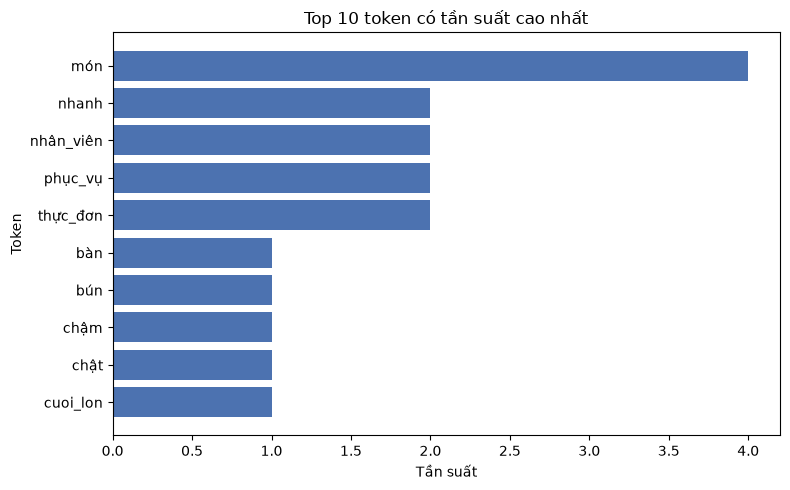

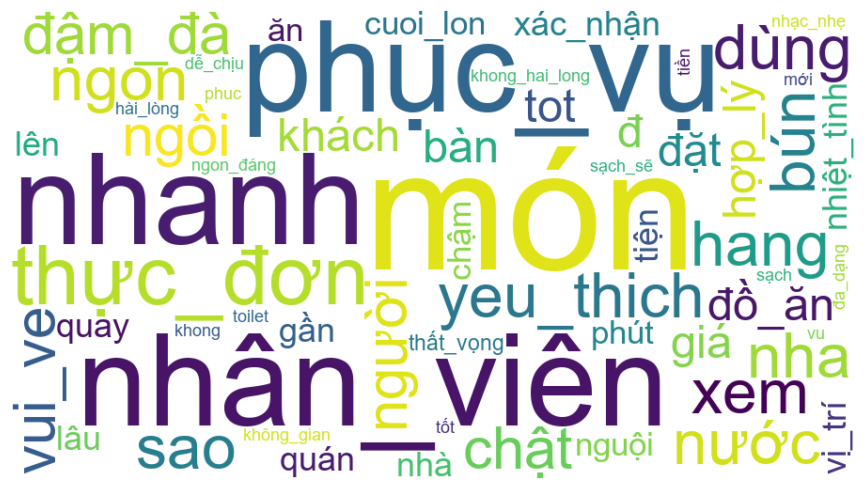

In [27]:
# --- Biểu đồ cột ngang top 10 token ---
plt.figure(figsize=(8, 5))
plt.barh(df_top10["token"], df_top10["tan_suat"], color="#4C72B0")
plt.xlabel("Tần suất")
plt.ylabel("Token")
plt.title("Top 10 token có tần suất cao nhất")
plt.gca().invert_yaxis()  # token tần suất cao nhất nằm trên cùng
plt.tight_layout()
plt.savefig("Cau2/bieu_do_top10.png", dpi=150)
plt.show()

# --- WordCloud ---
# Thử tìm font hỗ trợ tiếng Việt có dấu; nếu không có thì dùng font mặc định
duong_dan_font_uu_tien = r"C:\Windows\Fonts\arial.ttf"
if os.path.exists(duong_dan_font_uu_tien):
    font_path = duong_dan_font_uu_tien
else:
    print("Không tìm thấy font Arial, dùng font mặc định của WordCloud "
          "(có thể bị mất dấu tiếng Việt khi hiển thị).")
    font_path = None

wc = WordCloud(
    width=900, height=500, background_color="white", font_path=font_path
).generate_from_frequencies(dem_tan_suat)

plt.figure(figsize=(9, 5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.tight_layout()
plt.savefig("Cau2/wordcloud.png", dpi=150)
plt.show()

In [23]:
nhan_xet = """Nhận xét 1: Token 'món' có tần suất cao nhất (4 lần, xuất hiện ở NH02, NH05, NH07, NH10), gấp đôi các token đứng hạng 2 (tần suất 2) và chiếm 4/66 ≈ 6,1% tổng số token. Món ăn là chủ đề được nhắc nhiều nhất trong tập đánh giá nhà hàng; các token liên quan khác như 'bún', 'đồ_ăn', 'nước', 'dùng' chỉ xuất hiện 1 lần.

Nhận xét 2: Nhóm tần suất 2 gồm 4 token: 'nhanh' (NH01, NH04), 'nhân_viên' (NH01, NH05), 'phục_vụ' (NH01, NH07) và 'thực_đơn' (NH01, NH10). Như vậy, ngoài món ăn, các nội dung được nhắc lặp lại là nhân viên/phục vụ, tốc độ ('nhanh') và thực đơn. Đáng chú ý: cả 4 token này đều có mặt trong NH01 (một đánh giá dài nhiều từ), nên một đánh giá đơn lẻ đã góp một nửa tần suất cho cả nhóm hạng 2.

Nhận xét 3: Tần suất của 'phục_vụ' đang bị đếm thiếu: ở NH09, từ viết tắt "Pvu" được từ điển chuẩn hóa thành "phuc vu" (không dấu) nên bị tách thành 2 token 'phuc' và 'vu', không khớp với 'phục_vụ'. Nếu gộp lại, 'phục_vụ' sẽ có tần suất 3 và đứng riêng ở hạng 2. Tương tự, 'tot' (NH03, chuẩn hóa từ "ok") và 'tốt' (NH09) đang bị đếm thành 2 token khác nhau.

Nhận xét 4: Phân bố tần suất rất dàn trải: 10 đánh giá có 66 token, 59 token khác nhau, trong đó 54 token (≈ 92%) chỉ xuất hiện 1 lần và chỉ 5 token có tần suất ≥ 2. Do đó 5 vị trí cuối của top 10 ('bàn', 'bún', 'chậm', 'chật', 'cuoi_lon') đều chỉ có tần suất 1 và được chọn theo thứ tự alphabet khi bằng tần suất, không nổi bật hơn các token tần suất 1 khác. Wordcloud cũng thể hiện rõ: 'món' lớn nhất, 4 token hạng 2 lớn vừa, còn lại cỡ chữ gần như nhau."""

with open("Cau2/nhan_xet.txt", "w", encoding="utf-8") as f:
    f.write(nhan_xet.strip() + "
")

print(nhan_xet)

Nhận xét 1: Token 'món' có tần suất cao nhất (4 lần, xuất hiện ở NH02, NH05, NH07, NH10), gấp đôi các token đứng hạng 2 (tần suất 2) và chiếm 4/66 ≈ 6,1% tổng số token. Món ăn là chủ đề được nhắc nhiều nhất trong tập đánh giá nhà hàng; các token liên quan khác như 'bún', 'đồ_ăn', 'nước', 'dùng' chỉ xuất hiện 1 lần.

Nhận xét 2: Nhóm tần suất 2 gồm 4 token: 'nhanh' (NH01, NH04), 'nhân_viên' (NH01, NH05), 'phục_vụ' (NH01, NH07) và 'thực_đơn' (NH01, NH10). Như vậy, ngoài món ăn, các nội dung được nhắc lặp lại là nhân viên/phục vụ, tốc độ ('nhanh') và thực đơn. Đáng chú ý: cả 4 token này đều có mặt trong NH01 (một đánh giá dài nhiều từ), nên một đánh giá đơn lẻ đã góp một nửa tần suất cho cả nhóm hạng 2.

Nhận xét 3: Tần suất của 'phục_vụ' đang bị đếm thiếu: ở NH09, từ viết tắt "Pvu" được từ điển chuẩn hóa thành "phuc vu" (không dấu) nên bị tách thành 2 token 'phuc' và 'vu', không khớp với 'phục_vụ'. Nếu gộp lại, 'phục_vụ' sẽ có tần suất 3 và đứng riêng ở hạng 2. Tương tự, 'tot' (NH03, chu